# Spallation output analysis

Analyze `spallation_test.bin` produced by `spallation.cpp`. Records are five native-endian float64 values: `x, y, z` (pc), `E` (GeV/n), and `species_id`. IDs 0–9 are isotopes; −1 denotes a particle removed to the sink.

The source uses a spatially varying hydrogen density and diffusive trajectories. The matrix-exponential calculation below is therefore a homogeneous-gas benchmark, not an exact reproduction of the full transport simulation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import expm
from scipy.optimize import minimize_scalar

DATA_FILE = Path('spallation_test.bin')
if not DATA_FILE.exists():
    raise FileNotFoundError(f'{DATA_FILE.resolve()} not found; place/copy the output beside this notebook.')
raw = np.fromfile(DATA_FILE, dtype=np.float64)
if raw.size % 5:
    raise ValueError(f'File has {raw.size} float64 values, not a multiple of 5.')
data = raw.reshape(-1, 5)
x, y, z, energy, species_raw = data.T
species = np.rint(species_raw).astype(int)
if not np.allclose(species_raw, species):
    raise ValueError('Species IDs are not integer-valued.')
print(f'{len(data):,} records; {DATA_FILE.stat().st_size / 1e6:.2f} MB')
print('Species IDs found:', np.unique(species))

21,000 records; 0.84 MB
Species IDs found: [-1  0  1  2  3  4  5  6  7  8  9]


In [2]:
# Source-defined isotope order: IDs 0..9
isotopes = ['O16', 'N15', 'N14', 'C13', 'C12', 'B11', 'B10', 'Be10', 'Be9', 'Be7']
valid_ids = np.r_[np.arange(10), -1]
labels = isotopes + ['sink']
counts = pd.Series(species).value_counts().reindex(valid_ids, fill_value=0)
summary = pd.DataFrame({'count': counts.to_numpy(), 'fraction': counts.to_numpy() / len(species)}, index=labels)
display(summary)
if np.any(~np.isin(species, valid_ids)):
    print('Warning: unexpected species IDs:', np.unique(species[~np.isin(species, valid_ids)]))

,count,fraction
O16,621,0.029571
N15,385,0.018333
N14,317,0.015095
C13,273,0.013000
C12,1623,0.077286
B11,1177,0.056048
B10,695,0.033095
Be10,200,0.009524
Be9,370,0.017619
Be7,522,0.024857


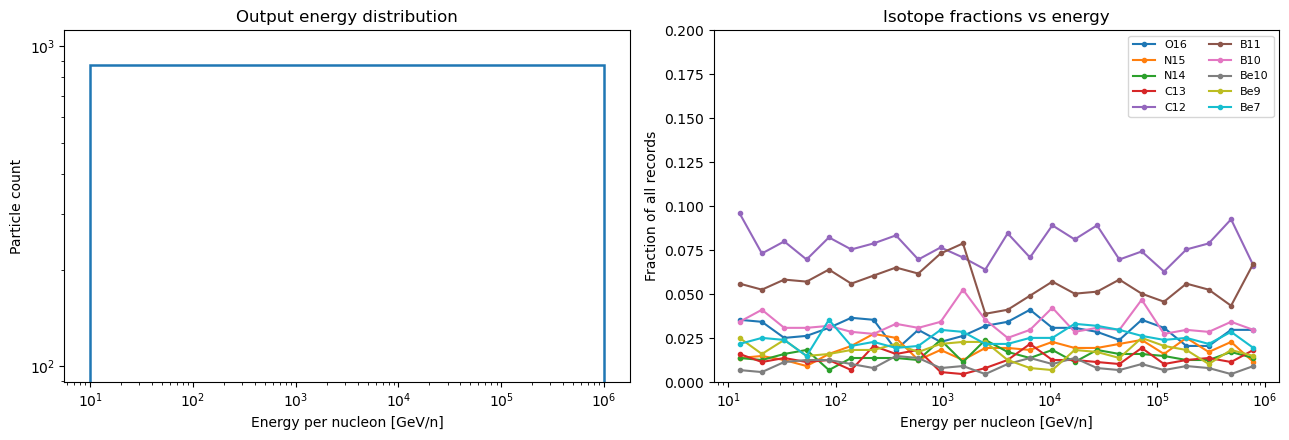

In [4]:
# Energy spectrum and isotope fractions in logarithmic energy bins
edges = np.logspace(np.log10(energy[energy > 0].min()), np.log10(energy.max()), 25)
centers = np.sqrt(edges[:-1] * edges[1:])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].hist(energy[energy > 0], bins=edges, histtype='step', lw=1.8)
ax[0].set(xscale='log', yscale='log', xlabel='Energy per nucleon [GeV/n]', ylabel='Particle count', title='Output energy distribution')
for sid, name in enumerate(isotopes):
    n, _ = np.histogram(energy[species == sid], bins=edges)
    total, _ = np.histogram(energy, bins=edges)
    frac = np.divide(n, total, out=np.full_like(n, np.nan, dtype=float), where=total > 0)
    ax[1].plot(centers, frac, marker='o', ms=3, label=name)
ax[1].set(xscale='log', xlabel='Energy per nucleon [GeV/n]', ylabel='Fraction of all records', ylim=(0, 1), title='Isotope fractions vs energy')
ax[1].legend(ncol=2, fontsize=8)
ax[1].set_ylim(0, 0.2)
plt.tight_layout()

x range: -1.7e+05 to 1.78e+05 pc; z range: -1.56e+05 to 1.94e+05 pc


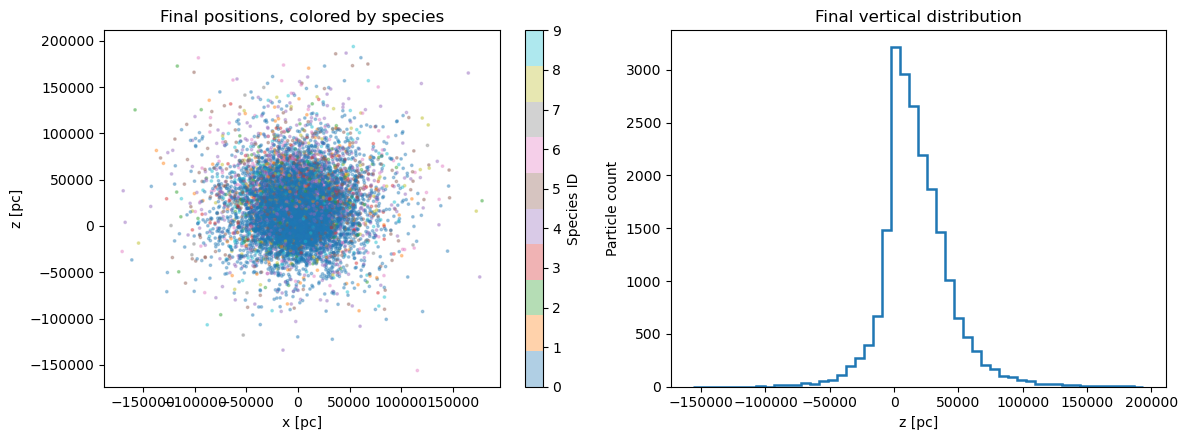

In [5]:
# Spatial diagnostics (positions are in pc)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sc = ax[0].scatter(x, z, c=species, s=3, alpha=.35, cmap='tab10', vmin=0, vmax=9)
ax[0].set(xlabel='x [pc]', ylabel='z [pc]', title='Final positions, colored by species')
fig.colorbar(sc, ax=ax[0], label='Species ID')
ax[1].hist(z, bins=50, histtype='step', lw=1.8)
ax[1].set(xlabel='z [pc]', ylabel='Particle count', title='Final vertical distribution')
plt.tight_layout()
print(f'x range: {x.min():.3g} to {x.max():.3g} pc; z range: {z.min():.3g} to {z.max():.3g} pc')

## Homogeneous-gas reaction-network benchmark

For each parent isotope, the diagonal cross section is its total destruction cross section. Off-diagonal entries are daughter-production cross sections; any remainder is assigned to the sink. Propagate the initial 10:1:10 O16:N14:C12 mixture with a continuous-time Markov generator for `T = 10^8 yr`. The density fit is an effective, phenomenological value that summarizes this spatially varying simulation; it should not be interpreted as a measured constant density.

In [6]:
# Cross sections in cm^2, in isotope order above (from cross_section.hpp)
sigma_1e27 = np.array([
    [293.2, 60.77, 30.07, 21.66, 33.16, 26.83, 10.40, 4.07, 3.35, 8.70],
    [0, 279.7, 20.15, 46.14, 43.82, 36.48, 13.59, 3.40, 7.98, 5.34],
    [0, 0, 265.9, 16.26, 52.00, 29.22, 10.16, 2.70, 2.71, 12.1],
    [0, 0, 0, 255.7, 56.73, 41.65, 4.70, 6.55, 7.52, 4.70],
    [0, 0, 0, 0, 237.1, 52.41, 18.08, 4.05, 7.32, 9.48],
    [0, 0, 0, 0, 0, 211.9, 40.85, 12.95, 15.15, 4.56],
    [0, 0, 0, 0, 0, 0, 197.1, 0, 13.95, 21.27],
    [0, 0, 0, 0, 0, 0, 0, 197.0, 36.37, 36.94],
    [0, 0, 0, 0, 0, 0, 0, 0, 181.7, 45.17],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 150.0],
]) * 1e-27
c_cm_s = 2.99792458e10
yr_s = 31557600.0
T_yr = 1e8
initial = np.zeros(11)
initial[[0, 2, 4]] = np.array([10, 1, 10]) / 21

def predicted_fractions(n_h):
    # Column-vector convention: dp/dt = Q @ p
    Q = np.zeros((11, 11))
    for parent in range(10):
        rate_factor = n_h * c_cm_s * yr_s
        Q[parent, parent] -= rate_factor * sigma_1e27[parent, parent]
        for daughter in range(parent + 1, 10):
            Q[daughter, parent] += rate_factor * sigma_1e27[parent, daughter]
        sink_sigma = sigma_1e27[parent, parent] - sigma_1e27[parent, parent + 1:].sum()
        Q[10, parent] += rate_factor * sink_sigma
    return expm(Q * T_yr) @ initial

# Fit n_H to the all-energy endpoint counts using a multinomial likelihood.
observed = np.array([np.sum(species == sid) for sid in range(10)] + [np.sum(species == -1)])
def negative_log_likelihood(log10_nh):
    p = np.clip(predicted_fractions(10.0 ** log10_nh), 1e-300, 1.0)
    return -np.dot(observed, np.log(p))
fit = minimize_scalar(negative_log_likelihood, bounds=(-6, 3), method='bounded')
n_h_eff = 10.0 ** fit.x
theory = predicted_fractions(n_h_eff)
print(f'Effective homogeneous n_H fit: {n_h_eff:.4g} cm^-3')
print(f'Multinomial deviance-like score (relative constant omitted): {2 * (fit.fun + np.sum(observed * np.log(np.maximum(observed / observed.sum(), 1e-300)))):.2f}')
print(f'Probability sum check: {theory.sum():.12f}')

Effective homogeneous n_H fit: 0.09957 cm^-3
Multinomial deviance-like score (relative constant omitted): 4.38
Probability sum check: 1.000000000000


,observed_count,observed_fraction,binomial_se,theory_fraction
O16,621,0.029571,0.001169,0.030079
N15,385,0.018333,0.000926,0.018362
N14,317,0.015095,0.000841,0.015466
C13,273,0.013000,0.000782,0.013293
C12,1623,0.077286,0.001843,0.076533
B11,1177,0.056048,0.001587,0.056100
B10,695,0.033095,0.001234,0.031642
Be10,200,0.009524,0.000670,0.009379
Be9,370,0.017619,0.000908,0.016793
Be7,522,0.024857,0.001074,0.026185


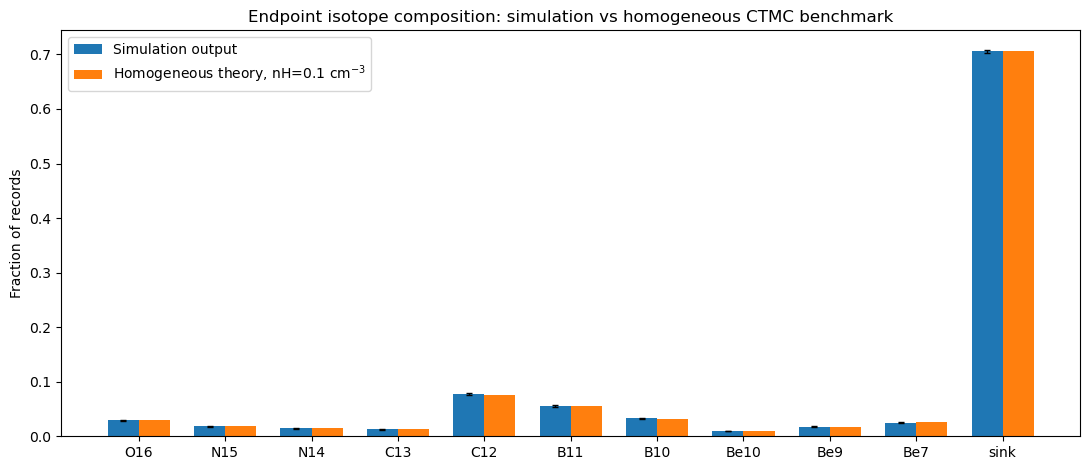

In [7]:
obs_fraction = observed / observed.sum()
obs_err = np.sqrt(obs_fraction * (1 - obs_fraction) / observed.sum())
fig, ax = plt.subplots(figsize=(11, 4.8))
ix = np.arange(11)
ax.bar(ix - .18, obs_fraction, width=.36, label='Simulation output')
ax.bar(ix + .18, theory, width=.36, label=f'Homogeneous theory, nH={n_h_eff:.2g} cm$^{{-3}}$')
ax.errorbar(ix - .18, obs_fraction, yerr=obs_err, fmt='none', ecolor='black', capsize=2, lw=1)
ax.set(xticks=ix, xticklabels=labels, ylabel='Fraction of records', title='Endpoint isotope composition: simulation vs homogeneous CTMC benchmark')
ax.legend()
plt.tight_layout()
comparison = pd.DataFrame({'observed_count': observed, 'observed_fraction': obs_fraction, 'binomial_se': obs_err, 'theory_fraction': theory}, index=labels)
display(comparison)

## Interpretation and checks

- The bin stores final particle records; confirm its output semantics in the current `spallation.cpp` before interpreting counts as a conserved cohort, especially if fragments create additional records or sink particles are retained.
- Energies are expected to remain at their injected values under the straight-ahead approximation.
- The matrix-exponential model captures the tabulated fragmentation network and sink, but not spatial transport, the position-dependent gas density, or trajectory-dependent exposure. A mismatch is therefore diagnostic rather than automatically a coding error.
- If the output omits sunk particles, the sink fraction in this notebook will be zero; the isotope fractions among surviving records should then be compared after renormalizing the theory over isotope states.